# OCR do Livro de Registro de Leis nº 1 — o que foi feito depois da entrega da v6

Este notebook reúne os três experimentos feitos depois da entrega da v6 (01/11/2026). Ele **não roda OCR**: lê os
resultados já registrados em `records/` (JSONs, figuras), gerados pelos scripts em `tools/` e pelo pipeline em
`ocr_pipeline/`. Cada número aponta para o arquivo de onde veio.

| experimento | pergunta |
|---|---|
| **E17** | Quanto a nossa pós-correção acrescenta, e como ela se compara com outros métodos de pós-correção sobre a mesma saída do reconhecedor? |
| **E18** | Dá para escolher o pré-processamento de imagem de um livro novo a partir de uma página de amostra, sem rótulos? |
| **E19** | O pipeline transfere, sem treino, para outro livro do mesmo acervo? E o recorte automático da página corta texto? |

**Protocolo comum.** Páginas de ajuste 5, 6, 8, 9, 11, 13, 14, 15, 16; reservadas 7, 10, 12 (GT oficial); teste com
10 páginas (18, 22, 23, 24, 25, 31, 32, 34, 44, 55; referência diplomática do Gemini). Nada é treinado ou selecionado em
reservadas ou teste. WER/CER normalizados, em nível de corpus. Comparações pareadas: bootstrap por blocos de 10
palavras de referência (10 000 reamostragens, seed 42, p por inversão de sinal), mais páginas ganhas/empatadas/perdidas.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
R = ROOT / 'records'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})


def load(path: str) -> dict:
    return json.loads((R / path).read_text(encoding='utf-8'))


def num(x: float, n: int = 2) -> str:
    return f'{x + 0.0:.{n}f}'.replace('.', ',').replace('-0,' + '0' * n, '0,' + '0' * n)


def ci(lo: float, hi: float) -> str:
    return f'[{num(lo)}; {num(hi)}]'


def table(header: list[str], rows: list[list]) -> None:
    lines = ['| ' + ' | '.join(header) + ' |', '|' + '---|' * len(header)]
    lines += ['| ' + ' | '.join(str(c) for c in row) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))


def wer_of(path: Path) -> tuple[float, float]:
    c = json.loads(path.read_text(encoding='utf-8'))['corpus']
    return 100 * c['wer_norm'], 100 * c['cer_norm']

## E17 — Pós-correção contra outros métodos

Todos os métodos leem **a mesma saída** do reconhecedor `st_c1m` (posteriors CTC das mesmas linhas). Assim a
diferença medida é só da pós-correção. Hiperparâmetros de cada método: escolhidos só nas 9 páginas de ajuste.

### Degraus da nossa pós-correção (GT oficial)

In [2]:
lad = load('postcorr/ladder_norm.json')
names = {'ladder_L0_raw': 'L0 CTC guloso', 'ladder_L1_rules': 'L1 + regras de texto',
         'ladder_L2_edit': 'L2 + palavra mais próxima do dicionário de época', 'ladder_L3_ctc': 'L3 + reescore CTC',
         'ladder_L4_tri': 'L4 + Viterbi de trigramas (básico)', 'ladder_L5b_bigram': 'v6 com bigrama no lugar do trigrama',
         'ladder_L5c_nobeam': 'v6 sem candidatos do beam', 'v6_all12_cache': '**v6**'}
table(['etapa', 'WER ajuste', 'WER reservadas', 'WER 12 páginas', 'CER 12 páginas', 'redução de WER (12 pág.)'],
      [[names[k], num(lad['tuning'][k]['wer']), num(lad['heldout'][k]['wer']), num(lad['all12'][k]['wer']),
        num(lad['all12'][k]['cer']), f"{num(lad['all12'][k]['wer_reduction_pct'], 1)}%"] for k in names])

| etapa | WER ajuste | WER reservadas | WER 12 páginas | CER 12 páginas | redução de WER (12 pág.) |
|---|---|---|---|---|---|
| L0 CTC guloso | 33,41 | 31,50 | 32,90 | 8,22 | 0,0% |
| L1 + regras de texto | 31,04 | 29,45 | 30,62 | 7,99 | 6,9% |
| L2 + palavra mais próxima do dicionário de época | 25,90 | 22,20 | 24,93 | 7,01 | 24,2% |
| L3 + reescore CTC | 23,48 | 20,16 | 22,60 | 6,10 | 31,3% |
| L4 + Viterbi de trigramas (básico) | 22,29 | 19,84 | 21,65 | 5,82 | 34,2% |
| v6 com bigrama no lugar do trigrama | 19,64 | 19,06 | 19,48 | 5,36 | 40,8% |
| v6 sem candidatos do beam | 19,92 | 19,21 | 19,73 | 5,34 | 40,0% |
| **v6** | 19,64 | 18,74 | 19,40 | 5,26 | 41,0% |

### Tabela final: v6 contra os outros métodos

- **A** pyctcdecode 0.5.0 + KenLM (n-gramas do mesmo corpus de época), 181 configurações buscadas no ajuste;
- **B** CTC Word Beam Search (Scheidl 2018; mesmo dicionário);
- **C** ByT5-small treinado com ruído sintético aprendido nas páginas de ajuste;
- **D** v6 + PortOldBERT (pseudo-log-verossimilhança no Viterbi da v6, λ escolhido no ajuste);
- **E** VLM Qwen2.5-VL-7B (protocolo one-shot de Thomas et al. 2026), vê o recorte da linha e o texto guloso.

Δ = WER(v6) − WER(método): negativo quer dizer que a v6 erra menos.

| método | WER reservadas | Δ v6 − método (IC95), p, páginas v6 ganha/empata/perde | WER teste | Δ idem |
|---|---|---|---|---|
| sem pós-correção (CTC guloso) | 31,50 |  | 11,54 |  |
| **v6 (nossa)** | **18,74** |  | **3,49** |  |
| A: pyctcdecode + KenLM | 20,00 | -1,26 [-3,01; 0,16], p=0,201, págs. 3/0/0 | 4,33 | -0,84 [-1,41; -0,26], p=0,007, págs. 6/2/2 |
| B: Word Beam Search | 20,31 | -1,57 [-3,15; 0,00], p=0,091, págs. 3/0/0 | 5,75 | -2,26 [-3,17; -1,35], p=0,000, págs. 10/0/0 |
| C: ByT5-small | 21,26 | -2,52 [-4,54; -0,63], p=0,020, págs. 3/0/0 | 6,86 | -3,36 [-4,41; -2,34], p=0,000, págs. 10/0/0 |
| D: v6 + PortOldBERT | 18,58 | 0,16 [0,00; 0,48], p=1,000, págs. 0/2/1 | 3,27 | 0,22 [-0,04; 0,49], p=0,184, págs. 0/6/4 |
| E: VLM Qwen2.5-VL-7B | 26,30 | -7,56 [-10,47; -4,69], p=0,000, págs. 3/0/0 | 18,05 | -14,55 [-16,01; -13,12], p=0,000, págs. 10/0/0 |

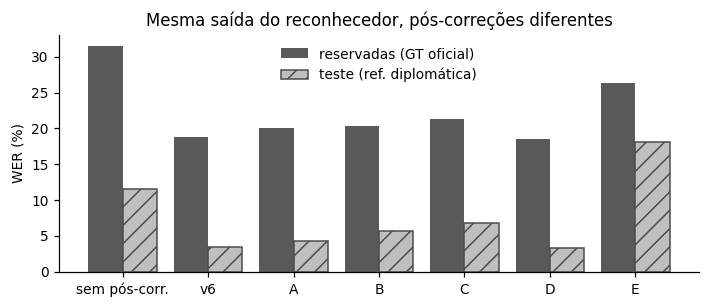

In [3]:
methods = [('A: pyctcdecode + KenLM', 'base_A2_pyctc', False), ('B: Word Beam Search', 'base_B2_wbs', False),
           ('C: ByT5-small', 'base_C_byt5', False), ('D: v6 + PortOldBERT', 'D_mlm_vs_v6', True),
           ('E: VLM Qwen2.5-VL-7B', 'base_E2_vlm_period', False)]
raw = {s: load(f'postcorr/curve/st_c1m_{s}.json')['wer_b'] for s in ('heldout', 'test')}
v6 = {s: load(f'postcorr/blocks/blk_{s}_base_A2_pyctc_10.json')['wer_a'] for s in ('heldout', 'test')}
rows, wers = [['sem pós-correção (CTC guloso)', num(raw['heldout']), '', num(raw['test']), '']], {}
rows.append(['**v6 (nossa)**', f"**{num(v6['heldout'])}**", '', f"**{num(v6['test'])}**", ''])
for label, key, flipped in methods:
    row = [label]
    for s in ('heldout', 'test'):
        b = load(f'postcorr/blocks/blk_{s}_{key}_10.json')
        wer = b['wer_a'] if flipped else b['wer_b']
        d, lo, hi = (-b['dwer'], -b['ci95'][1], -b['ci95'][0]) if flipped else (b['dwer'], *b['ci95'])
        w, t, l = b['pages_won_tied_lost']
        if flipped:
            w, l = l, w
        row += [num(wer), f"{num(d)} {ci(lo, hi)}, p={num(b['p_signflip'], 3)}, págs. {w}/{t}/{l}"]
        wers.setdefault(label, {})[s] = wer
    rows.append(row)
table(['método', 'WER reservadas', 'Δ v6 − método (IC95), p, páginas v6 ganha/empata/perde', 'WER teste', 'Δ idem'], rows)

fig, ax = plt.subplots(figsize=(7.5, 2.8))
labels = ['sem pós-corr.', 'v6'] + [m[0].split(':')[0] for m in methods]
vals = {s: [raw[s], v6[s]] + [wers[m[0]][s] for m in methods] for s in ('heldout', 'test')}
x = range(len(labels))
ax.bar([i - 0.2 for i in x], vals['heldout'], 0.4, color='0.35', label='reservadas (GT oficial)')
ax.bar([i + 0.2 for i in x], vals['test'], 0.4, color='0.75', hatch='//', edgecolor='0.3', label='teste (ref. diplomática)')
ax.set_xticks(list(x), labels)
ax.set_ylabel('WER (%)')
ax.legend(frameon=False)
ax.set_title('Mesma saída do reconhecedor, pós-correções diferentes')
plt.show()

**Leitura.**
- A v6 é a melhor no teste contra A, B, C e E com IC que exclui 0. Contra o A (KenLM, após busca justa de
  hiperparâmetros) a vantagem no teste é de ~0,8 ponto; nas reservadas (3 páginas) a diferença está dentro do ruído.
- D (v6 + modelo de linguagem mascarado) fica um pouco abaixo da v6, sem significância, e custa ~44 s de GPU por página.
- O VLM fica bem atrás da v6 nos dois conjuntos. No teste (referência diplomática) ele piora o texto em relação ao OCR
  cru (18,05 contra 11,54): moderniza grafia e acentos e inventa palavras plausíveis. Nas reservadas (GT oficial, que
  moderniza) ele melhora o cru (26,30 contra 31,50).

### Que erros cada método corrige (teste)
Para cada categoria de erro do OCR cru: quantos o método corrigiu e quantas palavras certas ele estragou.

In [4]:
et = load('postcorr/error_types_test.json')
cats = {'non_word': 'não-palavra', 'real_word': 'palavra real errada', 'short': 'palavras curtas',
        'numeral': 'numerais', 'split_merge': 'separação/junção', 'deleted': 'palavra perdida'}
runs = ['v6', 'A', 'B', 'C', 'VLM']
table(['categoria (erros no OCR cru)'] + [f'{r}: corrigidos / estragados' for r in runs],
      [[f"{cats[c]} ({et['runs']['v6'][c]['raw_errors']})"]
       + [f"{et['runs'][r][c]['fixed']} / {et['runs'][r][c]['broken']}" for r in runs] for c in cats])

| categoria (erros no OCR cru) | v6: corrigidos / estragados | A: corrigidos / estragados | B: corrigidos / estragados | C: corrigidos / estragados | VLM: corrigidos / estragados |
|---|---|---|---|---|---|
| não-palavra (177) | 161 / 0 | 137 / 2 | 131 / 11 | 107 / 14 | 76 / 28 |
| palavra real errada (33) | 18 / 9 | 18 / 3 | 9 / 1 | 9 / 5 | 9 / 156 |
| palavras curtas (18) | 11 / 1 | 10 / 0 | 5 / 0 | 7 / 4 | 8 / 33 |
| numerais (9) | 0 / 0 | 0 / 0 | 0 / 0 | 3 / 0 | 0 / 1 |
| separação/junção (4) | 0 / 0 | 2 / 0 | 2 / 1 | 3 / 1 | 0 / 2 |
| palavra perdida (19) | 1 / 0 | 1 / 0 | 3 / 0 | 3 / 2 | 3 / 3 |

A v6 resolve quase todas as não-palavras. O ponto fraco que sobra é a palavra real errada (lida como outra palavra
que existe). Numerais e separações/junções ela não corrige por construção.

### O ganho depende da qualidade do reconhecedor?
A mesma v6 aplicada a três reconhecedores (do mais fraco ao nosso).

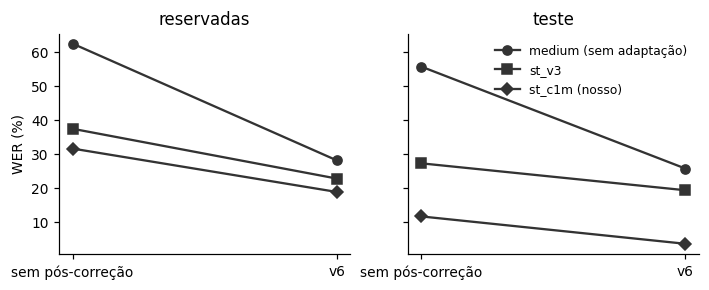

| reconhecedor | reservadas | Δ IC95 | teste | Δ IC95 |
|---|---|---|---|---|
| medium (sem adaptação) | 62,36 → 28,03 | [-38,81; -29,89] | 55,59 → 25,61 | [-32,07; -27,93] |
| st_v3 | 37,32 → 22,68 | [-17,68; -11,74] | 27,16 → 19,24 | [-9,17; -6,63] |
| st_c1m (nosso) | 31,50 → 18,74 | [-16,05; -9,61] | 11,54 → 3,49 | [-9,21; -6,89] |

In [5]:
recs = [('medium (sem adaptação)', 'medium'), ('st_v3', 'st_v3'), ('st_c1m (nosso)', 'st_c1m')]
rows = []
fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.6), sharey=True)
for ax, s, title in zip(axes, ('heldout', 'test'), ('reservadas', 'teste')):
    for (label, key), marker in zip(recs, 'osD'):
        b = load(f'postcorr/curve/{key}_{s}.json')
        ax.plot([0, 1], [b['wer_b'], b['wer_a']], marker=marker, color='0.2', label=label)
        if s == 'heldout':
            rows.append([label])
        rows[[r[0] for r in rows].index(label)] += [f"{num(b['wer_b'])} → {num(b['wer_a'])}", ci(*b['ci95'])]
    ax.set_xticks([0, 1], ['sem pós-correção', 'v6'])
    ax.set_title(title)
axes[0].set_ylabel('WER (%)')
axes[1].legend(frameon=False, fontsize=8)
plt.show()
table(['reconhecedor', 'reservadas', 'Δ IC95', 'teste', 'Δ IC95'], rows)

### Exemplos de linhas
Uma linha por situação, com o recorte da imagem, a referência e a saída de cada método (entre parênteses, o número de
palavras erradas). Seleção automática registrada em `records/postcorr/paper_examples/`.

**v6 corrige o que os outros não corrigem** — test10, página 23, linha 24

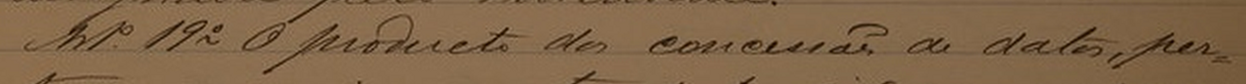

|  | texto (erros) |
|---|---|
| referência (normalizada) | art º 19 º o producto das concessões de datas pertence |
| raw | Art.º 19.º O producto das concessões de datas, per= (1) |
| v6 | Art.º 19.º O producto das concessões de datas, pertence (0) |
| A_pyctc | Art.º 19.º O producto das concessões de datas, pertence (0) |
| B_wbs | art.º 19.º o producto das concessões de datas, pertece (1) |
| C_byt5 | Art.º 19.º O producto das concessões de datas, pervence (1) |
| D_mlm | Art.º 19.º O producto das concessões de datas, pertence (0) |
| E_vlm | Art.º 19.º O produto das concessões de datas, perTence (1) |

**o VLM moderniza a grafia** — test10, página 55, linha 16

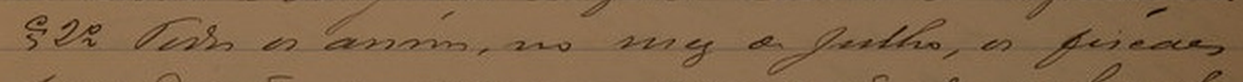

|  | texto (erros) |
|---|---|
| referência (normalizada) | 2 º todos os annos no mez de julho os fiscaes |
| raw | § 2.º Todos os annos, no mez de Julho, os fiscaes (0) |
| v6 | § 2.º Todos os annos, no mez de Julho, os fiscaes (0) |
| A_pyctc | § 2.º Todos os annos, no mez de Julho, os fiscaes (0) |
| B_wbs | § 2.º todos os annos, no mez de julho, os fiscaes (0) |
| C_byt5 | § 2.º Todos os annos, no mez de Julho, os fiscaes (0) |
| D_mlm | § 2.º Todos os annos, no mez de Julho, os fiscaes (0) |
| E_vlm | § 2.º Todos os anos, no mês de Julho, os fiscais (3) |

**onde o ByT5 é melhor** — test10, página 22, linha 29

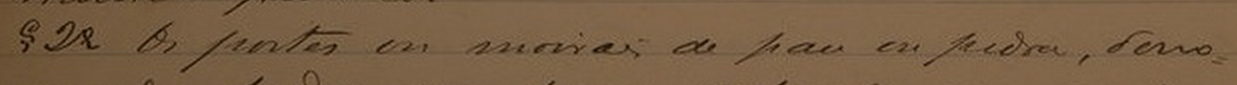

|  | texto (erros) |
|---|---|
| referência (normalizada) | º os postes ou moirões de pau ou pedra denominados |
| raw | § 2º Os postes ou moirões de pau ou pedra, deno= (2) |
| v6 | § 2º Os postes ou moitões de pau ou pedra, consummados (3) |
| A_pyctc | § 28 Os postes ou moirões de pau ou pedra, donorimados (2) |
| B_wbs | § 2º os postes ou moirões de pau ou pedra, donorimados (2) |
| C_byt5 | § 2.º Os postes ou moirões de pau ou pedra, denonumados (2) |
| D_mlm | § 2º Os postes ou moitões de pau ou pedra, consummados (3) |
| E_vlm | § 2º Os postes ou moirões de pau ou pedra, denonmiados (2) |

**onde a v6 estraga** — heldout, página 10, linha 18

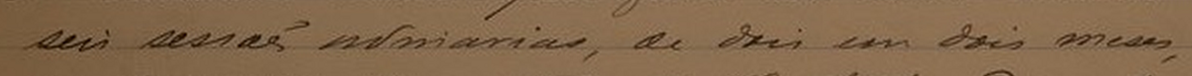

|  | texto (erros) |
|---|---|
| referência (normalizada) | seis sessões ordinarias de dois em dois meses |
| raw | seis sessões ordinarias, de dois em dois meses, (0) |
| v6 | seis sessões ordinarias, de dois em dois mezes, (1) |
| A_pyctc | seis sessões ordinarias, de dois em dois mezes, (1) |
| B_wbs | seis sessões ordinarias, de dois em dois meses, (0) |
| C_byt5 | seis sessões ordinarias, de dois em dois mezes, (1) |
| D_mlm | seis sessões ordinarias, de dois em dois mezes, (1) |
| E_vlm | seis sessões ordinárias, de dois em dois meses, (1) |

In [6]:
ex = load('postcorr/paper_examples/examples.json')
titles = {'v6_fixes_others_miss': 'v6 corrige o que os outros não corrigem', 'vlm_modernizes': 'o VLM moderniza a grafia',
          'byt5_better': 'onde o ByT5 é melhor', 'v6_breaks': 'onde a v6 estraga'}
shown = set()
for key, title in titles.items():
    e = next(x for x in ex[key] if (x['set'], x['page'], x['line']) not in shown)
    shown.add((e['set'], e['page'], e['line']))
    display(Markdown(f"**{title}** — {e['set']}, página {e['page']}, linha {e['line']}"))
    display(Image(filename=str(R / 'postcorr/paper_examples' / e['crop']), width=700))
    table(['', 'texto (erros)'], [['referência (normalizada)', e['ref']]]
          + [[m, f"{t} ({e['errors'][m]})"] for m, t in e['texts'].items()])

## E18 — Pré-processamento adaptativo a partir de uma página

Ideia: para um livro novo, testar combinações das operações de imagem que o pipeline já tem (contraste, CLAHE,
iluminação, gamma, canal, ruído, ampliação ×1/×2/×3, remoção de pautas...) numa **página de amostra** e escolher a
combinação com um critério **sem rótulos**. A busca é em duas etapas: 8 candidatos de segmentação, depois 13 de
imagem para o reconhecimento. Critérios comparados:

- `lex`: número de palavras da leitura gulosa que existem no léxico de época (top 100 mil);
- `conf`: confiança média do CTC; `conflex` = conf × lex;
- `stat`: aproximar as estatísticas da imagem (fundo, tinta, contraste, ruído, traço) das páginas do nosso livro;
- `oracle`: CER guloso na amostra **usando a transcrição dela** — o limite do que rótulos de uma página dariam.

### Seis degradações sintéticas das nossas páginas (WER nas reservadas)
A busca vê só a página de ajuste 6; a avaliação é a v6 completa nas reservadas 7, 10 e 12. Entre parênteses: parte do
dano da degradação que foi recuperada.

In [7]:
rep = load('e18/e18_report/e18_report.json')
names = {'uneven_light': 'iluminação desigual', 'low_contrast_cast': 'baixo contraste + dominante de cor',
         'faded_ink': 'tinta desbotada', 'bleed_through': 'tinta vazada do verso', 'jpeg_noise': 'JPEG + ruído',
         'low_res_blur': 'baixa resolução + desfoque'}
objs = ['conf', 'lex', 'stat', 'oracle']
rows = []
for s in rep['shifts']:
    cells = [names[s['shift']], num(s['wer']['default'])]
    for o in objs:
        rec = s['recovery'][o]
        note = '' if s['loss'] < 1 else (' (piora)' if rec < 0 else f' ({rec:.0%})')
        cells.append(num(s['wer'][o]) + note)
    rows.append(cells)
display(Markdown(f"Sem degradação, a v6 dá **{num(rep['clean'])}** nas reservadas."))
table(['degradação', 'padrão'] + objs, rows)
table(['degradação'] + [f'Spearman({o}, CER guloso)' for o in ('lex', 'conflex', 'conf', 'stat')],
      [[names[s['shift']]] + [num(s['spearman'][o]) for o in ('lex', 'conflex', 'conf', 'stat')] for s in rep['shifts']])

Sem degradação, a v6 dá **18,74** nas reservadas.

| degradação | padrão | conf | lex | stat | oracle |
|---|---|---|---|---|---|
| tinta vazada do verso | 19,21 | 19,21 | 19,21 | 20,47 | 19,53 |
| tinta desbotada | 20,16 | 19,69 (33%) | 19,06 (78%) | 20,00 (11%) | 19,37 (56%) |
| JPEG + ruído | 90,08 | 68,66 (30%) | 70,08 (28%) | 90,08 (0%) | 77,95 (17%) |
| baixo contraste + dominante de cor | 19,84 | 18,74 (100%) | 19,53 (29%) | 21,57 (piora) | 20,16 (piora) |
| baixa resolução + desfoque | 28,98 | 27,72 (12%) | 23,31 (55%) | 25,35 (35%) | 28,03 (9%) |
| iluminação desigual | 21,57 | 19,21 (83%) | 19,06 (89%) | 24,41 (piora) | 19,06 (89%) |

| degradação | Spearman(lex, CER guloso) | Spearman(conflex, CER guloso) | Spearman(conf, CER guloso) | Spearman(stat, CER guloso) |
|---|---|---|---|---|
| tinta vazada do verso | 0,95 | 0,94 | 0,69 | 0,76 |
| tinta desbotada | 0,94 | 0,95 | 0,92 | 0,62 |
| JPEG + ruído | 0,97 | 0,98 | 0,91 | 0,56 |
| baixo contraste + dominante de cor | 0,94 | 0,95 | 0,88 | 0,56 |
| baixa resolução + desfoque | 0,95 | 0,97 | 0,97 | 0,60 |
| iluminação desigual | 0,96 | 0,96 | 0,89 | 0,59 |

**Leitura.** O `lex` cumpre o critério definido antes de rodar: nas degradações que custam ≥ 2 pontos, recupera em
média 57% do dano (89%, 28%, 55%) e nunca piora em relação ao padrão. Ele também ordena os candidatos quase como o CER
real (Spearman 0,94–0,97). O `stat` ("deixar a imagem parecida com o nosso livro") falha: piora em 3 de 6. O oráculo
de uma página não é melhor que o `lex`.

Exemplo (iluminação desigual e baixa resolução): entrada degradada, imagem de segmentação padrão, e as imagens de
segmentação e de reconhecimento escolhidas pelo `lex`.

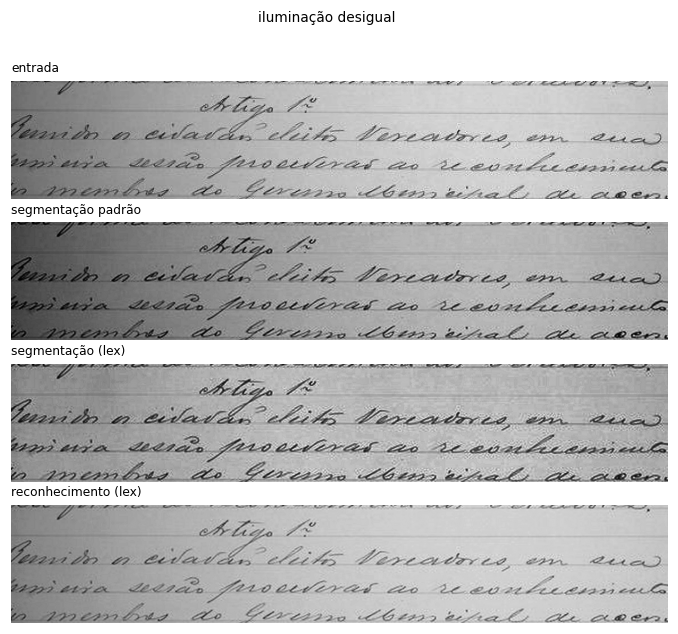

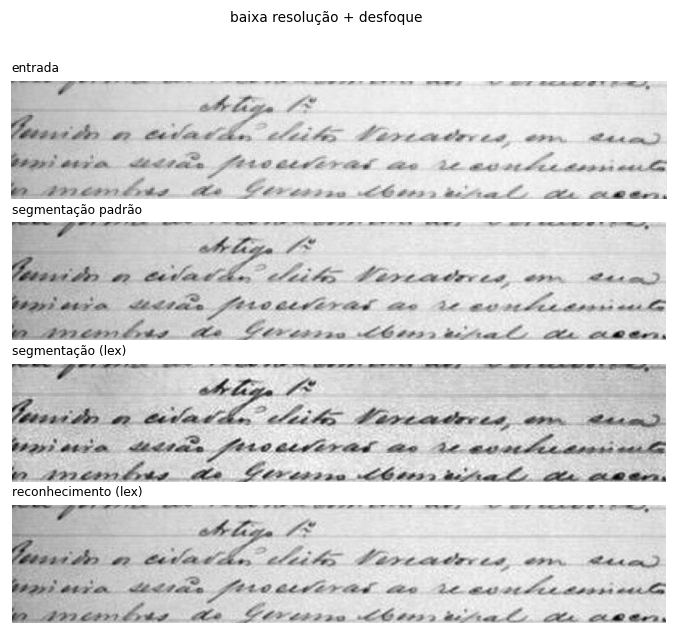

In [8]:
for shift in ('uneven_light', 'low_res_blur'):
    parts = [('input', 'entrada'), ('default_seg', 'segmentação padrão'), ('chosen_seg', 'segmentação (lex)'),
             ('chosen_rec', 'reconhecimento (lex)')]
    fig, axes = plt.subplots(4, 1, figsize=(9, 6.4))
    for ax, (part, title) in zip(axes, parts):
        ax.imshow(PILImage.open(R / f'e18/e18_figures/{shift}_{part}.png').convert('L'), cmap='gray')
        ax.set_title(title, fontsize=8, loc='left')
        ax.axis('off')
    fig.suptitle(names[shift], fontsize=9)
    plt.show()

### Controles
- **Identidade:** a busca inteira no nosso próprio livro, sem degradação. Um bom critério deve manter a cadeia padrão.
- **Cadeia fixa:** CLAHE + remoção de pautas em tudo (a escolha mais frequente do `lex` e do oráculo). Se ela fosse tão
  boa quanto o `lex`, o ganho viria do CLAHE, não de escolher por livro.

In [9]:
ident = {o: wer_of(R / f'e18/controls/identity/runs/{o}/result.json')[0] for o in ('default', 'lex', 'conf', 'stat', 'oracle')}
table(['identidade: critério', 'WER reservadas'], [[o, num(w)] for o, w in ident.items()])
rows = [['sem degradação', num(rep['clean']), num(wer_of(R / 'e18/controls/clean/runs/fixed_clahe/result.json')[0]),
         num(ident['lex'])]]
for s in rep['shifts']:
    rows.append([names[s['shift']], num(s['wer']['default']),
                 num(wer_of(R / f"e18/controls/{s['shift']}/runs/fixed_clahe/result.json")[0]), num(s['wer']['lex'])])
table(['degradação', 'padrão', 'cadeia fixa CLAHE', 'lex'], rows)

| identidade: critério | WER reservadas |
|---|---|
| default | 18,74 |
| lex | 18,74 |
| conf | 20,16 |
| stat | 19,21 |
| oracle | 19,69 |

| degradação | padrão | cadeia fixa CLAHE | lex |
|---|---|---|---|
| sem degradação | 18,74 | 18,43 | 18,74 |
| tinta vazada do verso | 19,21 | 19,53 | 19,21 |
| tinta desbotada | 20,16 | 19,37 | 19,06 |
| JPEG + ruído | 90,08 | 89,45 | 70,08 |
| baixo contraste + dominante de cor | 19,84 | 20,16 | 19,53 |
| baixa resolução + desfoque | 28,98 | 26,30 | 23,31 |
| iluminação desigual | 21,57 | 20,00 | 19,06 |

O `lex` mantém o padrão no próprio livro (18,74). O `conf` piora +1,4 e o oráculo de uma página sobreajusta. O `lex` é
melhor que a cadeia fixa em todas as 6 degradações: o ganho vem de escolher por livro.

### Livros reais: 4 processos do TraPrInq (Inquisição portuguesa, séc. XVI–XIX)
Validação do TraPrInq (Zenodo 13986218, CC BY 4.0), com transcrição diplomática em PAGE XML. Cada processo é tratado
como um livro novo: 1 página de amostra para a busca, v6 nas demais. O reconhecedor nunca viu essas mãos, então o
erro absoluto é alto. O que importa é a comparação dentro de cada livro.

In [10]:
rows = []
for case in sorted((R / 'e18/books').glob('PT-*')):
    cells = [case.name.replace('PT-TT-TSO-', '')]
    same_file = case / 'same_as.txt'  # configs identical to an earlier one were not re-run
    same = dict(l.split('/')[-1].split(' = ') for l in same_file.read_text().split('\n') if ' = ' in l) if same_file.exists() else {}
    for o in ('default', 'lex', 'conf', 'oracle'):
        if o in same:
            cells.append(f'= {same[o]}')
            continue
        w, c = wer_of(case / f'runs/{o}/result.json')
        cells.append(f'{num(w)} / {num(c)}')
    rows.append(cells)
table(['processo', 'padrão (WER / CER)', 'lex', 'conf', 'oracle'], rows)

| processo | padrão (WER / CER) | lex | conf | oracle |
|---|---|---|---|---|
| IL-028-CX1622-16125 | 62,87 / 25,92 | 62,00 / 26,06 | 63,05 / 26,72 | 71,45 / 32,69 |
| IL-28-12955 | 81,84 / 46,63 | 81,84 / 43,32 | = lex | = lex |
| IL-28-7123 | 73,04 / 38,15 | 67,76 / 32,86 | 69,76 / 32,23 | 68,34 / 31,50 |
| IL-28-7196 | 74,66 / 36,51 | 72,48 / 34,18 | 73,99 / 33,54 | = conf |

O `lex` fica igual ou melhor que o padrão em WER nos 4 processos (0 a −5,3 pontos). São 4 livros e 18 páginas:
evidência de direção, sem IC. Uma checagem de segmentação contra as linhas do PAGE XML (`records/e18/seg/`) mostrou
recall de 93–100% para todos os candidatos: o ganho vem da imagem entregue ao reconhecedor, não de achar mais linhas.

## E19 — Um livro novo do mesmo acervo, sem treino

**Livro de Atas da Câmara Municipal de São Carlos, 1894–1902** (fotos da Pró-Memória): outro escrivão, atas em vez de
leis. 50 fotos (fólios 36–65, 1895–1896) com transcrição do Gemini. O sorteio, feito antes de qualquer OCR, separou 3
páginas de amostra para a busca, 20 de avaliação e deixou 27 sem uso. O reconhecedor e a pós-correção são os da v6,
sem nenhum treino; só a cadeia de pré-processamento é escolhida nas 3 amostras.

### v6 nas 20 páginas de avaliação (referência Gemini)

| critério | cadeia escolhida (segmentação) | WER | CER | Δ WER vs padrão (IC95), p, págs. ganha/empata/perde |
|---|---|---|---|---|
| padrão | contraste, ×2 (v6) | 22,50 | 7,26 |  |
| lex | CLAHE, ×2 | 21,14 | 7,02 | -1,36 [-2,38; -0,36], p=0,011, págs. 12/4/4 |
| oracle | contraste, ×3 | 21,39 | 6,98 | -1,11 [-2,18; -0,05], p=0,051, págs. 10/3/7 |

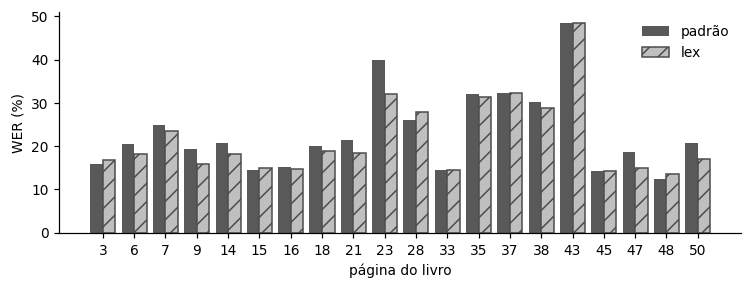

In [11]:
rep19 = load('e19/e19_report.json')
cfg = {'default': 'contraste, ×2 (v6)', 'lex': 'CLAHE, ×2', 'oracle': 'contraste, ×3'}
rows = [['padrão', cfg['default'], num(100 * rep19['runs']['default']['wer_norm']),
         num(100 * rep19['runs']['default']['cer_norm']), '']]
for o in ('lex', 'oracle'):
    b = load(f'e19/bootstrap_default_vs_{o}.json')  # a = default, b = chosen; dwer = a - b
    w, t, l = b['pages_won_tied_lost']
    rows.append([o, cfg[o], num(100 * rep19['runs'][o]['wer_norm']), num(100 * rep19['runs'][o]['cer_norm']),
                 f"{num(-b['dwer'])} {ci(-b['ci95'][1], -b['ci95'][0])}, p={num(b['p_signflip'], 3)}, págs. {l}/{t}/{w}"])
table(['critério', 'cadeia escolhida (segmentação)', 'WER', 'CER', 'Δ WER vs padrão (IC95), p, págs. ganha/empata/perde'], rows)

pp = {o: rep19['runs'][o]['per_page'] for o in ('default', 'lex')}
pages = sorted(pp['default'], key=int)
fig, ax = plt.subplots(figsize=(8, 2.6))
x = range(len(pages))
ax.bar([i - 0.2 for i in x], [pp['default'][p] for p in pages], 0.4, color='0.35', label='padrão')
ax.bar([i + 0.2 for i in x], [pp['lex'][p] for p in pages], 0.4, color='0.75', hatch='//', edgecolor='0.3', label='lex')
ax.set_xticks(list(x), pages)
ax.set_xlabel('página do livro')
ax.set_ylabel('WER (%)')
ax.legend(frameon=False)
plt.show()

**Leitura.** O critério definido antes de rodar (lex ≤ padrão e nunca pior por mais de 1 ponto) foi cumprido: o `lex`
é melhor, com IC que exclui 0. A escolha sem rótulos foi tão boa quanto a com rótulos das amostras. Os critérios que não
rodaram completos: `conflex` escolhe a mesma cadeia que o `lex`; `conf` e `stat` escolhem segmentações piores nas
amostras e na avaliação (tabela abaixo), então a v6 completa não foi rodada para eles.

### Segmentação contra as linhas das transcrições
Os 8 candidatos de segmentação nas 20 páginas de avaliação, comparando as linhas encontradas com as 773 linhas
transcritas (pareamento por texto; CER guloso, sem pós-correção).

In [12]:
sw = rep19['seg_weak']
rows = []
for name, s in sorted(sw.items(), key=lambda kv: kv[1]['greedy_cer']):
    rows.append([name, f"{s['found']} ({s['recall']:.1%})".replace('.', ','), s['extra'], s['split'], s['missed'],
                 num(100 * s['greedy_cer'])])
table(['cadeia de segmentação', 'linhas encontradas', 'extras', 'partidas', 'perdidas', 'CER guloso'], rows)

| cadeia de segmentação | linhas encontradas | extras | partidas | perdidas | CER guloso |
|---|---|---|---|---|---|
| up2|clahe+remove_rules | 730 (94,4%) | 16 | 3 | 5 | 13,23 |
| up3|contrast+remove_rules | 727 (94,0%) | 13 | 8 | 5 | 13,35 |
| up2|contrast+remove_rules | 727 (94,0%) | 13 | 5 | 4 | 13,47 |
| up2|illumination+remove_rules | 724 (93,7%) | 17 | 6 | 6 | 14,02 |
| up2|illumination+contrast+remove_rules | 732 (94,7%) | 26 | 2 | 5 | 14,20 |
| up2|none | 695 (89,9%) | 77 | 15 | 6 | 14,83 |
| up1|contrast+remove_rules | 714 (92,4%) | 16 | 6 | 5 | 16,51 |
| up2|denoise+contrast+remove_rules | 713 (92,2%) | 21 | 4 | 4 | 17,07 |

A escolha do `lex` (up2 CLAHE) também é a melhor segmentação por CER nas páginas de avaliação. O que mais pesa é
remover as pautas: sem isso aparecem 77 linhas extras.

### Recorte automático da página
O livro 2 não tem os recortes manuais do livro 1. O `ocr_pipeline/auto_crop.py` recorta a partir da foto: acha a logo
d'água da Pró-Memória e pinta por cima, acha o papel e corta só margens sem tinta. A regra é nunca cortar traço.

In [13]:
c = rep19['crop']
b1h = rep19['book1_runs']['hand']
b1a = rep19['book1_runs']['auto']
bo = load('e19/bootstrap_book1_hand_vs_auto_official.json')
bg = load('e19/bootstrap_book1_hand_vs_auto_gemini.json')
table(['verificação (primeiro recorte)', 'resultado'], [
    ['livro 1: linhas do Kraken dentro do recorte', f"automático {c['book1']['auto_inside']}/{c['book1']['lines']}, manual {c['book1']['hand_inside']}/{c['book1']['lines']} (o manual corta a rubrica)"],
    ['livro 1, v6, GT oficial (WER/CER)', f"manual {num(100 * b1h['wer_norm'])} / {num(100 * b1h['cer_norm'])}; automático {num(100 * b1a['wer_norm'])} / {num(100 * b1a['cer_norm'])}; auto − manual {num(-bo['dwer'])} {ci(-bo['ci95'][1], -bo['ci95'][0])}, p={num(bo['p_signflip'])}"],
    ['livro 1, v6, ref. Gemini (WER/CER)', f"manual {num(100 * b1h['vs_gemini']['wer_norm'])} / {num(100 * b1h['vs_gemini']['cer_norm'])}; automático {num(100 * b1a['vs_gemini']['wer_norm'])} / {num(100 * b1a['vs_gemini']['cer_norm'])}; auto − manual {num(-bg['dwer'])} {ci(-bg['ci95'][1], -bg['ci95'][0])}, p={num(bg['p_signflip'])}"],
    ['livro 2: linhas do Kraken dentro', f"{c['book2']['inside']}/{c['book2']['lines']}; {len(c['book2']['outside_photos'])} fotos com linha fora"],
    ['TraPrInq (504 páginas, outro acervo): linhas do PAGE XML dentro', f"{c['pagexml']['inside']}/{c['pagexml']['lines']} ({c['pagexml']['inside'] / c['pagexml']['lines']:.1%})".replace('.', ',')],
])

| verificação (primeiro recorte) | resultado |
|---|---|
| livro 1: linhas do Kraken dentro do recorte | automático 375/375, manual 367/375 (o manual corta a rubrica) |
| livro 1, v6, GT oficial (WER/CER) | manual 19,40 / 5,26; automático 19,94 / 5,33; auto − manual 0,54 [-0,49; 1,57], p=0,34 |
| livro 1, v6, ref. Gemini (WER/CER) | manual 8,61 / 3,37; automático 8,33 / 2,86; auto − manual -0,28 [-1,08; 0,51], p=0,56 |
| livro 2: linhas do Kraken dentro | 1977/1986; 8 fotos com linha fora |
| TraPrInq (504 páginas, outro acervo): linhas do PAGE XML dentro | 13072/13497 (96,9%) |

No livro 2, das 8 fotos com linha fora, só 2 eram texto cortado de verdade (rubrica e número do fólio na borda: fotos
81 e 107). As outras eram linhas segmentadas passando da borda do papel ou linhas falsas sobre a logo pintada. No
TraPrInq, papel escuro, manchado ou muito escrito fazia o limiar separar papel de tinta em vez de papel de fundo.

**Duas correções (recorte v2):** (1) manter blocos de escrita que encostam na borda do papel; (2) caixa do papel como
união da caixa simples com uma caixa sobre a luminosidade "fechada" (tinta apagada). Comparação, só das caixas:

| conjunto | primeiro recorte | recorte v2 |
|---|---|---|
| TraPrInq: linhas dentro | 13072/13497 | 13476/13497 (99,84%); 0 páginas pioram |
| livro 2: caixas que mudam |  | 9/50, todas contêm a antiga |
| livro 1: caixas que mudam |  | 100/106, área ×1,13 no máximo |

**livro 2, foto 81: a rubrica "Souza Franco 39" na borda direita volta para dentro**

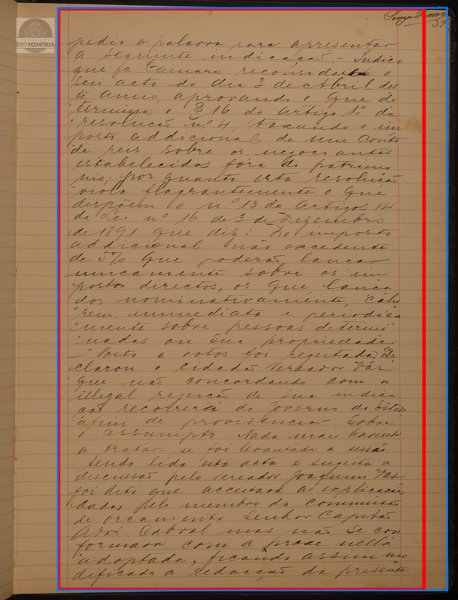

**TraPrInq 16809_m0014b: o caso que o recorte v2 ainda não resolvia (metade de baixo fora)**

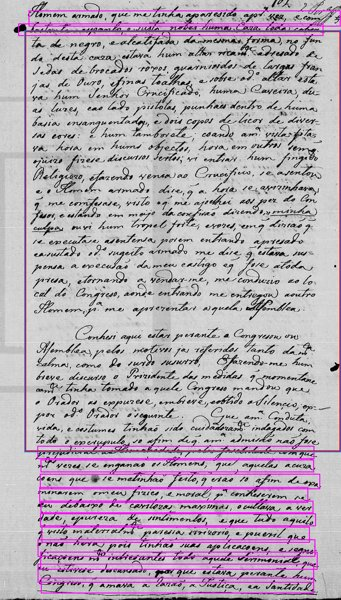

In [14]:
t = load('e19/crop2_traprinq.json')
b2 = load('e19/crop2_book2.json')
b1 = load('e19/crop2_book1.json')
n = sum(r['n_lines'] for r in t)
worse = sum(r['inside_new'] < r['inside_old'] for r in t)
table(['conjunto', 'primeiro recorte', 'recorte v2'], [
    ['TraPrInq: linhas dentro', f"{sum(r['inside_old'] for r in t)}/{n}", f"{sum(r['inside_new'] for r in t)}/{n} ({sum(r['inside_new'] for r in t) / n:.2%}); {worse} páginas pioram".replace('.', ',')],
    ['livro 2: caixas que mudam', '', f"{sum(r['old'] != r['new'] for r in b2)}/50, {'todas contêm a antiga' if all(r['contains'] for r in b2) else 'nem todas contêm a antiga'}"],
    ['livro 1: caixas que mudam', '', f"{sum(r['old'] != r['new'] for r in b1)}/{len(b1)}, área ×{num(max(r['area_ratio'] for r in b1))} no máximo"],
])
for f, title in [('crop2_book2_81.jpg', 'livro 2, foto 81: a rubrica "Souza Franco 39" na borda direita volta para dentro'),
                 ('crop2_traprinq_16809_m0014b.jpg', 'TraPrInq 16809_m0014b: o caso que o recorte v2 ainda não resolvia (metade de baixo fora)')]:
    display(Markdown(f'**{title}**'))
    display(Image(filename=str(R / 'e19/figures' / f), width=420))

A página 16809_m0014b não tem fundo: linhas de escrita muito densa ficam com menos de 50% de "papel" e quebram a
faixa. A correção (tapar buracos de até 1% também na caixa simples, sem nunca encolher a caixa v2) está no branch
`exp/e19-crop-gap` e sendo validada nos três conjuntos.

## Ressalvas e o que está em aberto

- **Referências.** O teste do livro 1 e todo o E19 usam transcrições do Gemini, não revisadas por pessoas; a `st_c1m`
  foi treinada com rótulos do Gemini de outras páginas, o que torna os números absolutos otimistas. O GT oficial das
  reservadas moderniza a grafia. Com só 3 páginas, as reservadas são indicativas.
- **E17** compara pós-correções sobre a mesma saída. Ainda não há comparação de **sistemas completos** (reconhecedor
  da literatura + sua decodificação, com os mesmos dados de treino): o plano está escrito (E20).
- **E18/E19:** um livro novo do mesmo acervo (20 páginas, 30 fólios seguidos de um escrivão) e 4 processos do
  TraPrInq. Evidência de direção forte no E19 (IC exclui 0), fraca no TraPrInq (sem IC).
- **Recorte v2** está sendo passado pela v6 completa para confirmar que os números do E19 e do livro 1 não mudam.
- **Uso:** o caminho opcional para outro livro (recorte automático → busca `lex` → batch) está no README do repositório.